# 01 - Exploratory data analysis

Descriptive statistics, missingness, seasonality and predictor association on the cleaned station-day panel. The tables shown here are saved as `results/Exploratory_Data.csv` and `results/Exploratory_temporal.csv`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd

from config import DATA_PROCESSED, RESULTS_DIR, FIGURES_DIR, SEED

df = pd.read_csv(DATA_PROCESSED / "cleaned_daily.csv", parse_dates=["timestamp"])
print(f"{len(df):,} station-days | {df.station_id.nunique()} stations | "
      f"{df.timestamp.min():%Y-%m-%d} to {df.timestamp.max():%Y-%m-%d}")

40,983 station-days | 95 stations | 2016-11-25 to 2026-04-06


## Cleaning audit

Raw rows, removals by reason and the retained panel.

In [2]:
import json
audit = json.loads((ROOT / 'data' / 'processed' / 'audit.json').read_text(encoding='utf-8'))
cleaning = audit['cleaning']
print('input rows        :', f"{cleaning['input_rows']:,}")
print('removed total     :', f"{cleaning['removed_total']:,}")
print('removed by reason :', cleaning['removed_by_reason_mutually_exclusive'])
print('retained rows     :', f"{len(df):,}")

input rows        : 41,718
removed total     : 735
removed by reason : {'invalid_timestamp': 0, 'missing_target': 0, 'target_le_min': 727, 'target_ge_max': 8, 'duplicate_station_day_dropped': 0}
retained rows     : 40,983


## Descriptive table

One row per variable, with missingness, quantiles and outlier counts.

In [3]:
from config import load_project_config
from pm25_project.eda import exploratory_table

cfg, _ = load_project_config()
table = exploratory_table(df, cfg, audit)
table.set_index('variable')[['family', 'unit', 'n_total', 'n_missing', 'pct_missing',
                             'min', 'median', 'max', 'mean', 'std', 'skewness']].round(3)

,family,unit,n_total,n_missing,pct_missing,min,median,max,mean,std,skewness
variable,,,,,,,,,,,
timestamp,metadata,NaN,40983,0,0.000,1.480032e+15,1.694563e+15,1.775434e+15,1.675831e+15,7.293744e+13,-0.807
pm25,Target,ug/m3,41718,0,0.000,7.000000e-03,7.851000e+00,4.849820e+02,9.458000e+00,9.730000e+00,17.829
temperature_celsius,Meteorological,degC,40983,0,0.000,-1.279000e+00,1.849500e+01,3.486600e+01,1.827200e+01,6.386000e+00,-0.102
pressure_mb,Meteorological,hPa,40983,0,0.000,9.303170e+02,9.977290e+02,1.033662e+03,9.938170e+02,1.718000e+01,-1.087
wind_u,Meteorological,m/s,40983,0,0.000,-1.109900e+01,2.060000e-01,9.662000e+00,3.430000e-01,2.528000e+00,-0.178
wind_v,Meteorological,m/s,40983,0,0.000,-1.086000e+01,4.300000e-02,8.486000e+00,-1.790000e-01,1.386000e+00,-1.277
no2,NO2,mol/m2,40983,2407,5.873,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,2.123
co,CO,mol/m2,40983,2407,5.873,1.300000e-02,3.100000e-02,9.800000e-02,3.200000e-02,4.000000e-03,1.398
o3,O3,mol/m2,40983,2448,5.973,1.040000e-01,1.400000e-01,2.290000e-01,1.440000e-01,1.400000e-02,1.151


## Distributions

PM2.5 is strongly right-skewed; AOD is dimensionless and gases are reported in mol/m2.

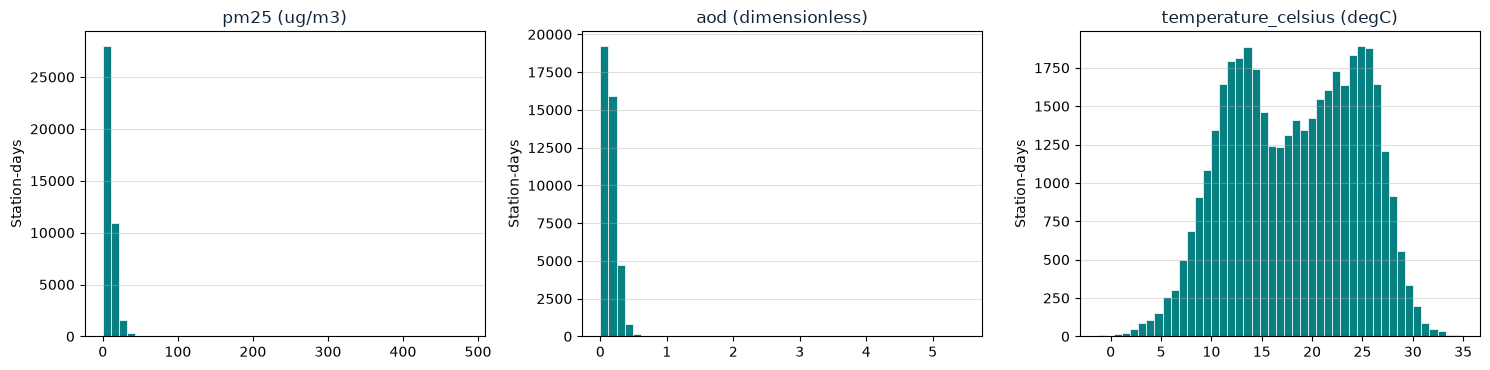

In [4]:
%matplotlib inline
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, column, unit in zip(axes, ['pm25', 'aod', 'temperature_celsius'],
                            ['ug/m3', 'dimensionless', 'degC']):
    ax.hist(df[column].dropna(), bins=45, color='#087F80', edgecolor='white', linewidth=0.5)
    ax.set_title(f'{column} ({unit})', color='#10243A')
    ax.set_ylabel('Station-days')
    ax.grid(axis='y', alpha=0.4)
fig.tight_layout()

## Missingness

Meteorology and AOD are complete; the three gases carry roughly 6% missing values.

In [5]:
missing = df.drop(columns=['timestamp', 'datetime_utc', 'date']).isna().mean().mul(100).sort_values(ascending=False)
missing[missing > 0].round(2).to_frame('pct_missing')

,pct_missing
o3,5.97
no2,5.87
co,5.87


## Seasonality

Seasonal means and the share of station-days above 25 and 50 ug/m3.

In [6]:
from pm25_project.eda import seasonal_table

seasons = seasonal_table(df)
seasons.round(2)

,season,n_days,mean,median,std,q95,max,pct_days_above_25,pct_days_above_50
0,DJF,8938,10.94,8.77,11.72,26.75,399.40,6.15,0.45
1,JJA,12766,9.59,8.50,7.21,20.46,234.88,1.95,0.15
2,MAM,9276,8.25,6.83,7.40,18.64,303.50,1.92,0.36
3,SON,10003,9.08,7.47,12.02,20.32,484.98,2.46,0.25


## Predictor association

Spearman correlation with PM2.5, strongest first.

In [7]:
pairs = pd.read_csv(RESULTS_DIR / 'correlations.csv')
rows = pd.concat([
    pairs[pairs.variable_a.eq('pm25')][['variable_b', 'spearman_rho']].rename(columns={'variable_b': 'variable'}),
    pairs[pairs.variable_b.eq('pm25')][['variable_a', 'spearman_rho']].rename(columns={'variable_a': 'variable'}),
])
rows = rows.rename(columns={'spearman_rho': 'rho'})
rows.reindex(rows.rho.abs().sort_values(ascending=False).index).round(3)

,variable,rho
4,no2,0.247
7,aod,0.180
1,pressure_mb,0.167
2,wind_u,-0.164
6,o3,-0.135
3,wind_v,0.097
0,temperature_celsius,0.064
5,co,0.036
